In [37]:
import os
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from astropy.coordinates import SkyCoord
import astropy.units as u

from astrodendro import Dendrogram
from photutils.segmentation import SegmentationImage, deblend_sources
from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

from skimage.measure import regionprops
from skimage.morphology import disk, dilation
from skimage import measure

from tqdm.notebook import tqdm
#%matplotlib widget

In [38]:
def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan

    lo, hi = np.nanpercentile(x, [pmin, pmax])
    x = (x - lo) / (hi - lo)
    x = np.clip(x, 0, 1)
    return x 

In [39]:
def clean_map(x):
    y = np.array(x, dtype=float, copy=True)
    y[~np.isfinite(y)] = 0.0
    y[y < 0] = 0.0
    return y

In [40]:
def mask_pn_cat(cat, wcs, shape, radius_factor=2.0):
    mask = np.zeros(shape, dtype=bool)

    coords = SkyCoord(cat["RAdeg"].values * u.deg, cat["DEdeg"].values * u.deg)
    x, y = wcs.world_to_pixel(coords)

    yy, xx = np.indices(shape)

    for xi, yi, fwhm_arcsec in zip(x, y, cat["FWHM"].values):
        if not np.isfinite(xi) or not np.isfinite(yi):
            continue

        r_pix = radius_factor * fwhm_arcsec / pix_scale
        source_mask = (xx - xi)**2 + (yy - yi)**2 <= r_pix**2
        mask |= source_mask

    return mask

In [41]:
def comp_dendro(input_den, err_med, sigma, delta_sigma, npix):
    d = Dendrogram.compute(
        input_den,
        min_value=sigma * err_med,
        min_delta=delta_sigma * err_med,
        min_npix=npix)

    labels_dendro = np.zeros(input_den.shape, dtype=np.int32)
    for i, leaf in enumerate(d.leaves, start=1):
        labels_dendro[leaf.get_mask()] = i

    print(f"Astrodendro leaves count: {len(d.leaves)}")

    show = labels_dendro.astype(float)
    show[show == 0] = np.nan
    return labels_dendro, show

In [42]:
def conv (labels, detection, npix):
    binary_mask = labels > 0

    smooth_mask = ndi.gaussian_filter(binary_mask.astype(float), sigma=2.0)
    smooth_mask = smooth_mask > 0.4
    
    connected_labels, n_connected = ndi.label(smooth_mask)
    
    print(f"Number of regions after smoothing: {n_connected}")
    
    segm = SegmentationImage(connected_labels.astype(np.int32))
    deblend_data = clean_map(detection)
    
    labels_final = deblend_sources(
        deblend_data, segm, n_pixels=npix,
        n_levels=32, contrast=0.001)
    
    print(f"final deblended regions: {labels_final.data.astype(np.int32).max()}")

    show = labels_final.data.astype(np.int32).astype(float)
    show[show == 0] = np.nan

    return labels_final, show
    

In [43]:
def safe_ratio(num, den):
    out = np.full_like(num, np.nan, dtype=float)
    mask = np.isfinite(num) & np.isfinite(den) & (den > 0) & (num > 0)
    out[mask] = num[mask] / den[mask]
    return out

In [44]:
def sum_in_mask(arr, mask):
    x = np.array(arr, dtype=float)
    good = np.isfinite(x)
    return np.nansum(x[mask & good])

In [45]:
def err_sum_in_mask(err, mask):
    e = np.array(err, dtype=float)
    good = np.isfinite(e) & (e > 0)
    return np.sqrt(np.nansum(e[mask & good]**2))

In [46]:
def classify_bpt(log_nii_ha, log_oiii_hb):
    if not (np.isfinite(log_nii_ha) and np.isfinite(log_oiii_hb)):
        return "unclassified_BPT"

    kewley = 0.61 / (log_nii_ha - 0.47) + 1.19
    kauff  = 0.61 / (log_nii_ha - 0.05) + 1.30

    if log_nii_ha < 0.05 and log_oiii_hb < kauff:
        return "HII_BPT_clean"
    elif log_nii_ha < 0.47 and log_oiii_hb < kewley:
        return "HII_BPT_possible"
    else:
        return "non_HII_BPT"

In [47]:
def make_cat(labels_data):
    rows = []

    nlab = int(np.nanmax(labels_data))
    for lab in range(1, nlab + 1):
        mask = labels_data == lab
        npix = int(mask.sum())
        if npix == 0:
            continue

        F_ha = sum_in_mask(ha, mask)
        F_hb = sum_in_mask(hb, mask)
        F_oiii = sum_in_mask(oiii, mask)
        F_nii = sum_in_mask(nii, mask)
        F_sii = sum_in_mask(sii, mask)

        E_ha = err_sum_in_mask(ha_err, mask)
        E_hb = err_sum_in_mask(hb_err, mask)
        E_oiii = err_sum_in_mask(oiii_err, mask)
        E_nii = err_sum_in_mask(nii_err, mask)
        E_sii = err_sum_in_mask(sii_err, mask)

        sn_ha = F_ha / E_ha if E_ha > 0 else np.nan
        sn_hb = F_hb / E_hb if E_hb > 0 else np.nan
        sn_oiii = F_oiii / E_oiii if E_oiii > 0 else np.nan
        sn_nii = F_nii / E_nii if E_nii > 0 else np.nan
        sn_sii = F_sii / E_sii if E_sii > 0 else np.nan

        sii_ha = F_sii / F_ha if F_ha > 0 and F_sii > 0 else np.nan
        nii_ha = F_nii / F_ha if F_ha > 0 and F_nii > 0 else np.nan
        oiii_hb = F_oiii / F_hb if F_hb > 0 and F_oiii > 0 else np.nan
        pn_r = F_oiii / (F_ha + F_nii) if (F_ha + F_nii) > 0 and F_oiii > 0 else np.nan

        log_sii_ha = np.log10(sii_ha) if np.isfinite(sii_ha) else np.nan
        log_nii_ha = np.log10(nii_ha) if np.isfinite(nii_ha) else np.nan
        log_oiii_hb = np.log10(oiii_hb) if np.isfinite(oiii_hb) else np.nan

        yy, xx = np.where(mask)
        xcen = np.mean(xx)
        ycen = np.mean(yy)

        ra, dec = wcs.wcs_pix2world(xcen, ycen, 0)

        bpt_class = classify_bpt(log_nii_ha, log_oiii_hb)

        is_snr_like = np.isfinite(sii_ha) and (sii_ha >= 0.4) and (sn_sii > 3) and (sn_ha > 3)
        is_dig_like = np.isfinite(sii_ha) and (sii_ha >= 0.3) and (sn_sii > 3) and (sn_ha > 3)

        rows.append({
            "region_id": lab,
            "npix": npix,
            "x": xcen,
            "y": ycen,
            "ra": ra,
            "dec": dec,

            "F_ha": F_ha,
            "F_hb": F_hb,
            "F_oiii": F_oiii,
            "F_nii": F_nii,
            "F_sii": F_sii,

            "sn_ha": sn_ha,
            "sn_hb": sn_hb,
            "sn_oiii": sn_oiii,
            "sn_nii": sn_nii,
            "sn_sii": sn_sii,

            "sii_ha": sii_ha,
            "nii_ha": nii_ha,
            "oiii_hb": oiii_hb,
            "pn_r": pn_r,

            "log_sii_ha": log_sii_ha,
            "log_nii_ha": log_nii_ha,
            "log_oiii_hb": log_oiii_hb,

            "bpt_class": bpt_class,
            "snr_like": is_snr_like,
            "dig_like": is_dig_like,})

    return pd.DataFrame(rows)

In [48]:
def plot_region_contours(base_image, labels_data, region_ids, title, contour_color="red"):
    fig, ax = plt.subplots(figsize=(10, 10))
    
    ax.imshow(base_image, origin="lower")

    count_drawn = 0

    for rid in region_ids:
        mask = labels_data == rid

        if not np.any(mask):
            continue

        contours = measure.find_contours(mask.astype(float), level=0.5)

        for contour in contours:
            ax.plot(contour[:, 1], contour[:, 0], color=contour_color, linewidth=1.3)

        count_drawn += 1

    ax.set_title(f"{title} ({count_drawn} regions)")
    ax.set_xlabel("x [pix]")
    ax.set_ylabel("y [pix]")
    plt.tight_layout()
    plt.show()

In [49]:
pix_scale = 0.2
psf_fwhm_arcsec = 0.85
psf_fwhm_pix = psf_fwhm_arcsec / pix_scale

In [50]:
path = "ADP.2025-07-06T07_52_11.876.fits"
hdul = fits.open(path, memmap=True)
for i, h in enumerate(hdul):
        print(f"{i:3d}  {h.name:25s}")
        if i==30:
            break

  0  PRIMARY                  
  1  ID                       
  2  FLUX                     
  3  SNR                      
  4  SNRBIN                   
  5  BIN_ID                   
  6  V_STARS                  
  7  FORM_ERR_V_STARS         
  8  SIGMA_STARS              
  9  FORM_ERR_SIGMA_STARS     
 10  H3_STARS                 
 11  FORM_ERR_H3_STARS        
 12  H4_STARS                 
 13  FORM_ERR_H4_STARS        
 14  CHI2_TOT                 
 15  HEII4685_FLUX            
 16  HEII4685_FLUX_ERR        
 17  HEII4685_VEL             
 18  HEII4685_VEL_ERR         
 19  HEII4685_SIGMA           
 20  HEII4685_SIGMA_ERR       
 21  HEII4685_SIGMA_CORR      
 22  HEII4685_MOM0            
 23  HEII4685_MOM0_ERR        
 24  HEII4685_MOM1            
 25  HEII4685_MOM1_ERR        
 26  HEII4685_MOM2            
 27  HEII4685_MOM2_ERR        
 28  HB4861_FLUX              
 29  HB4861_FLUX_ERR          
 30  HB4861_VEL               


In [51]:
ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data
sii6716 = hdul["SII6716_FLUX"].data
sii6730 = hdul["SII6730_FLUX"].data
sii = sii6716 + sii6730

ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data
sii6716_err = hdul["SII6716_FLUX_ERR"].data
sii6730_err = hdul["SII6730_FLUX_ERR"].data
sii_err = np.sqrt(sii6716_err**2 + sii6730_err**2)

In [52]:
header = hdul["HA6562_FLUX"].header
wcs = WCS(header)

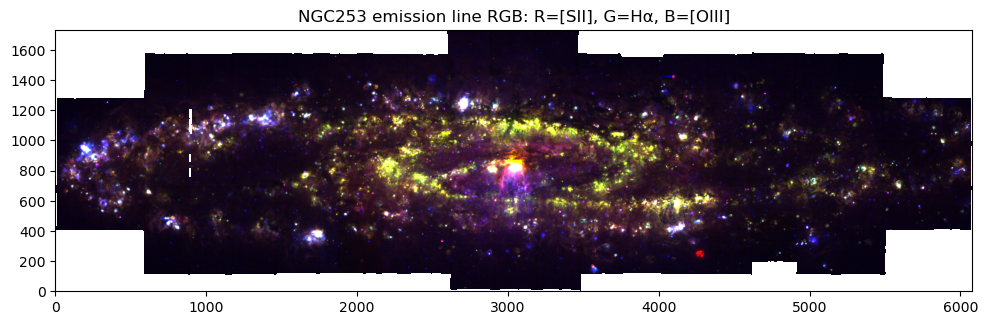

In [53]:
rgb = np.dstack([percentile_norm(sii),percentile_norm(ha),percentile_norm(oiii)])

plt.figure(figsize=(10, 5))
plt.imshow(rgb, origin="lower")
plt.title("NGC253 emission line RGB: R=[SII], G=H\u03B1, B=[OIII]")
plt.tight_layout()
plt.show()

In [54]:
pn_cat = pd.read_csv("PN_CAT.csv")

pn_mask = mask_pn_cat(pn_cat, wcs, ha.shape, radius_factor=2.0)

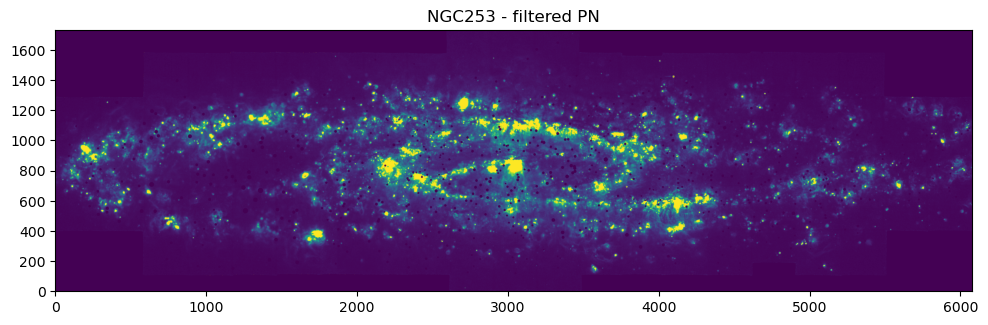

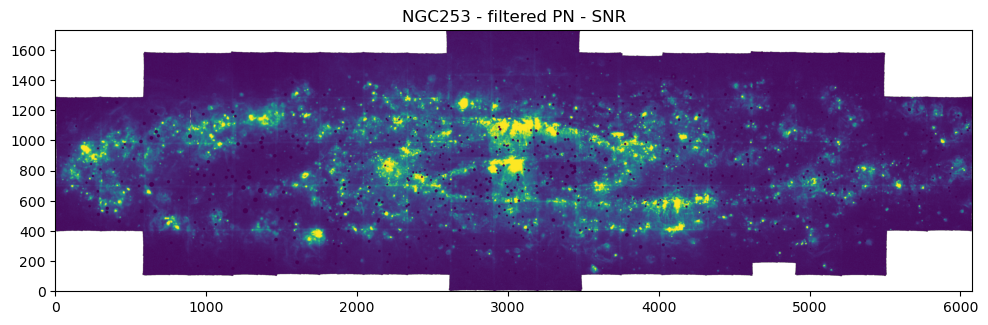

In [55]:
detection = clean_map(ha + oiii)
detection[pn_mask] = 0.0
detection_err = np.sqrt(ha_err**2 + oiii_err**2)
err_med = np.nanmedian(detection_err[np.isfinite(detection_err) & (detection_err > 0)])

detection_snr = np.full_like(detection, np.nan, dtype=float)
good = np.isfinite(detection) & np.isfinite(detection_err) & (detection_err > 0)
detection_snr[good] = detection[good] / detection_err[good]
detection_snr[pn_mask] = 0.0

plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(detection), origin="lower")
plt.title("NGC253 - filtered PN")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(detection_snr), origin="lower")
plt.title("NGC253 - filtered PN - SNR")
plt.tight_layout()
plt.show()

In [56]:
labels_1, i1 = comp_dendro(detection, err_med, 25, 25, 500)
labels_2, i2 = comp_dendro(detection, err_med, 25, 25, 300)
labels_3, i3= comp_dendro(detection, err_med, 40, 40, 500)
labels_4, i4 = comp_dendro(detection_snr, 1.0, 25, 25, 500)

Astrodendro leaves count: 445
Astrodendro leaves count: 659
Astrodendro leaves count: 314
Astrodendro leaves count: 354


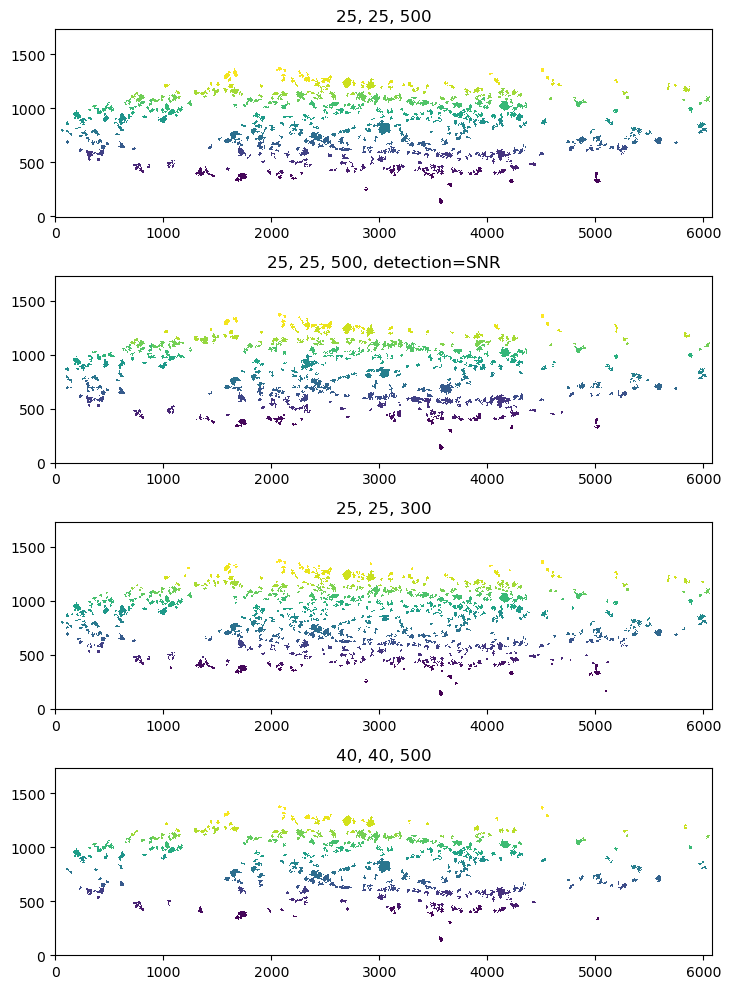

In [57]:
fig = plt.figure(figsize=(20,10))

ax = fig.add_subplot(411)
ax.imshow(i1, origin='lower', interpolation='none')
ax.set_title('25, 25, 500')

ax = fig.add_subplot(413)
ax.imshow(i2, origin='lower', interpolation='none')
ax.set_title('25, 25, 300')

ax = fig.add_subplot(414)
ax.imshow(i3, origin='lower', interpolation='none')
ax.set_title('40, 40, 500')

ax = fig.add_subplot(412)
ax.imshow(i4, origin='lower', interpolation='none')
ax.set_title('25, 25, 500, detection=SNR')

plt.tight_layout()
plt.show()

In [58]:
conv_label_1, show_1 = conv(labels_1, detection, 500)
conv_label_2, show_2 = conv(labels_2, detection, 300)
conv_label_3, show_3 = conv(labels_3, detection, 500)
conv_label_4, show_4 = conv(labels_4, detection_snr, 500)

Number of regions after smoothing: 347


Deblending:   0%|          | 0/212 [00:00<?, ?it/s]

final deblended regions: 425
Number of regions after smoothing: 521


Deblending:   0%|          | 0/340 [00:00<?, ?it/s]

final deblended regions: 639
Number of regions after smoothing: 249


Deblending:   0%|          | 0/146 [00:00<?, ?it/s]

final deblended regions: 300
Number of regions after smoothing: 276


Deblending:   0%|          | 0/169 [00:00<?, ?it/s]

final deblended regions: 354


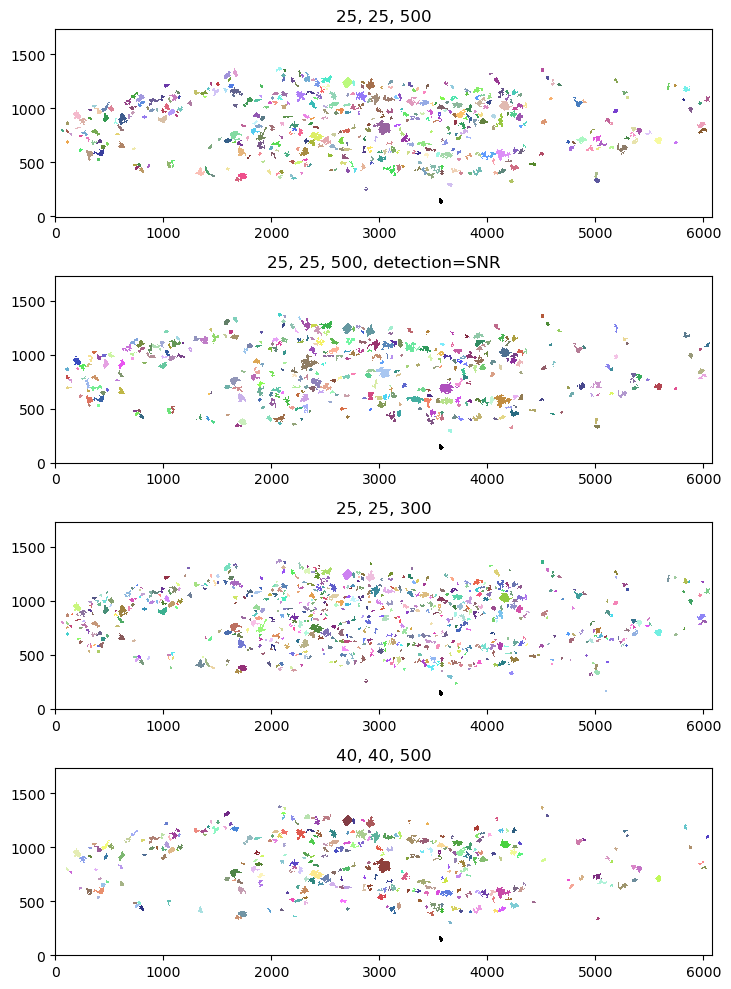

In [59]:
fig = plt.figure(figsize=(20,10))

ax = fig.add_subplot(411)
ax.imshow(show_1, cmap=conv_label_1.make_cmap(), origin='lower', interpolation='none')
ax.set_title('25, 25, 500')

ax = fig.add_subplot(413)
ax.imshow(show_2, cmap=conv_label_2.make_cmap(), origin='lower', interpolation='none')
ax.set_title('25, 25, 300')

ax = fig.add_subplot(414)
ax.imshow(show_3, cmap=conv_label_3.make_cmap(), origin='lower', interpolation='none')
ax.set_title('40, 40, 500')

ax = fig.add_subplot(412)
ax.imshow(show_4, cmap=conv_label_4.make_cmap(), origin='lower', interpolation='none')
ax.set_title('25, 25, 500, detection=SNR')

plt.tight_layout()
plt.show()

In [60]:
labels_data = conv_label_2.data.astype(np.int32)

sii_oiii = safe_ratio(sii, oiii)
log_sii_oiii = np.log10(sii_oiii)

sii_ha = safe_ratio(sii, ha)
log_sii_ha = np.log10(sii_ha)

valid_ipm = (np.isfinite(log_sii_oiii) & np.isfinite(log_sii_ha))

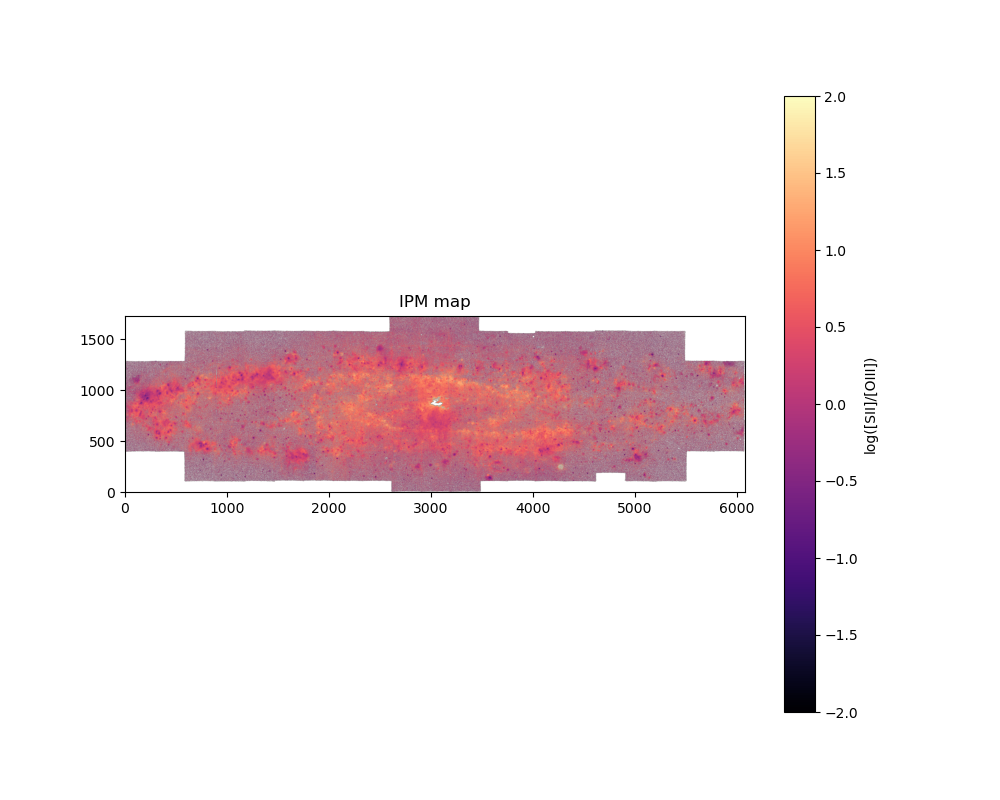

In [61]:
%matplotlib widget

plt.figure(figsize=(10, 8))
plt.imshow(log_sii_oiii, origin="lower", cmap="magma", vmin=-2, vmax=2)
plt.colorbar(label=r"log([SII]/[OIII])")
plt.title("IPM map")
plt.show()

In [62]:
base_labels = labels_data.copy()
new_labels = base_labels.copy()

max_expand_pix = 10
min_detection_snr = 3.0

seed_cat = make_cat(base_labels)

hii_seed_ids = seed_cat.loc[
    seed_cat["bpt_class"].isin(["HII_BPT_clean", "HII_BPT_possible"])
    & (~seed_cat["snr_like"]),"region_id"].astype(int).to_numpy()

growth_rows = []

for rid in tqdm(hii_seed_ids[:25], desc="IPM boundary growth"):
    mask = base_labels == rid

    if mask.sum() < 20:
        continue

    search_area = dilation(mask, disk(max_expand_pix))
    grow_area = search_area & (new_labels == 0)

    if grow_area.sum() == 0:
        continue

    outer = dilation(mask, disk(max_expand_pix + 4))
    inner = dilation(mask, disk(max_expand_pix))
    annulus = outer & (~inner) & (base_labels == 0) & np.isfinite(ha)

    if annulus.sum() > 20:
        local_bg = np.nanmedian(ha[annulus])
        bg_sigma = 1.4826 * np.nanmedian(np.abs(ha[annulus] - local_bg))
    else:
        good_ha = np.isfinite(ha)
        local_bg = np.nanmedian(ha[good_ha])
        bg_sigma = np.nanstd(ha[good_ha])

    inside_ipm = log_sii_oiii[mask & valid_ipm]
    if len(inside_ipm) == 0:
        continue

    high_ipm = np.nanpercentile(inside_ipm, 80)

    add_pixels = (
        grow_area
        & valid_ipm
        & np.isfinite(detection_snr)
        & (detection_snr >= min_detection_snr)
        & (ha > local_bg + bg_sigma)
        & (log_sii_oiii <= high_ipm + 0.05))

    if add_pixels.sum() == 0:
        continue

    old_npix = int(mask.sum())
    new_labels[add_pixels] = rid

    growth_rows.append({
        "region_id": int(rid),
        "old_npix": old_npix,
        "new_npix": int(old_npix + add_pixels.sum()),
        "added_npix": int(add_pixels.sum()),
        "local_bg_ha": local_bg,
        "local_bg_sigma_ha": bg_sigma})

labels_refined = new_labels.astype(np.int32)
growth_summary = pd.DataFrame(growth_rows)
growth_summary.head()

IPM boundary growth:   0%|          | 0/25 [00:00<?, ?it/s]

,region_id,old_npix,new_npix,added_npix,local_bg_ha,local_bg_sigma_ha
0,1,1783,2761,978,179.499039,54.379719
1,2,359,611,252,137.772797,61.725853
2,3,479,862,383,248.627945,68.435104
3,4,673,1289,616,208.350876,73.169777
4,5,1428,2135,707,369.279266,93.338196


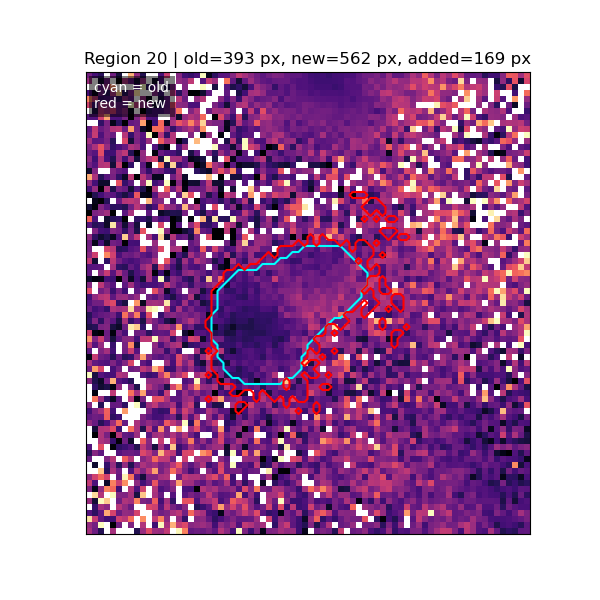

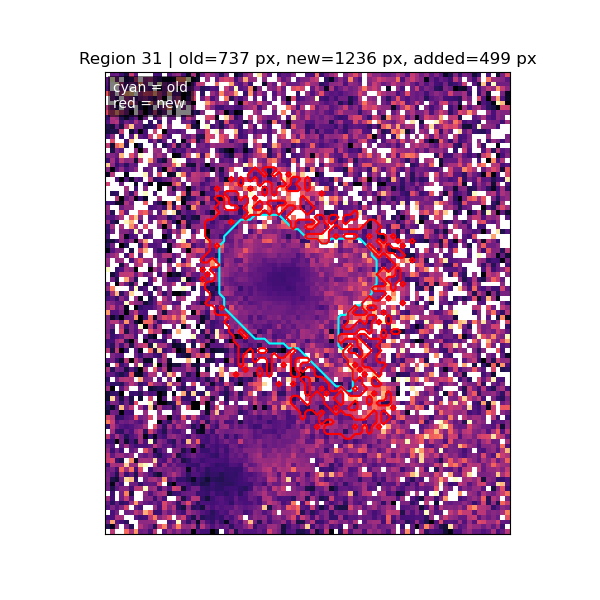

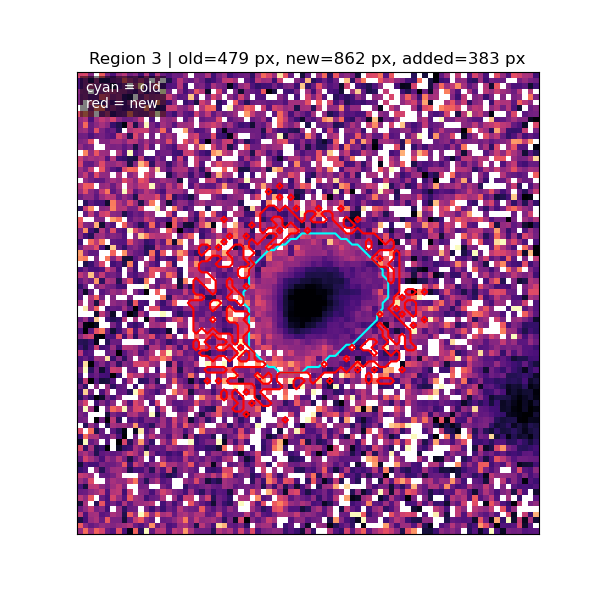

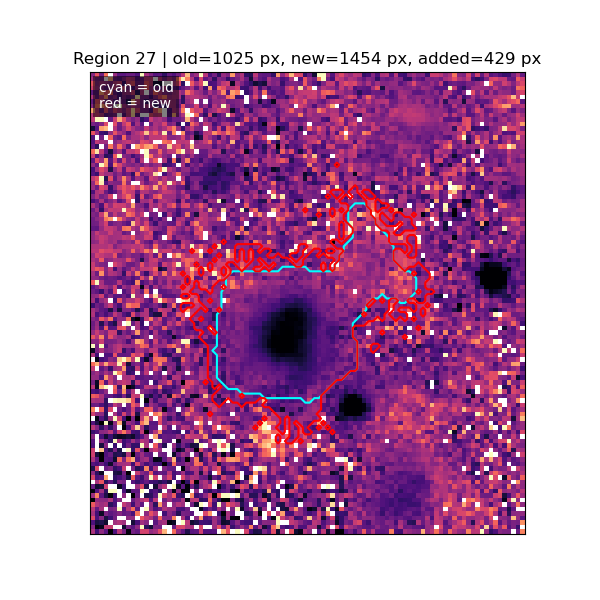

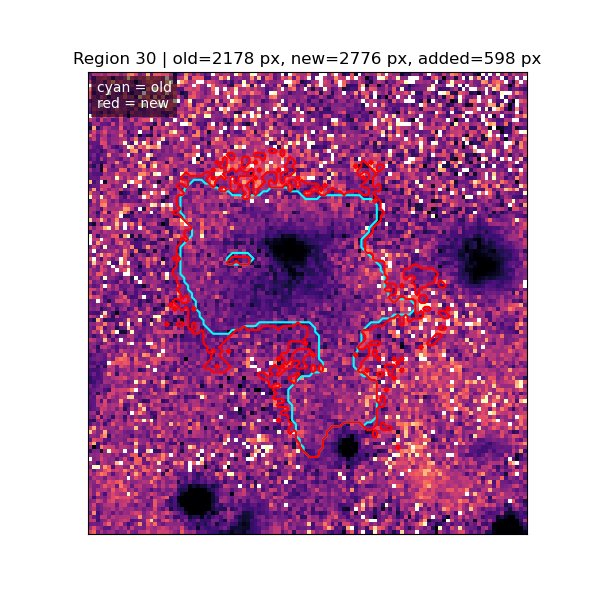

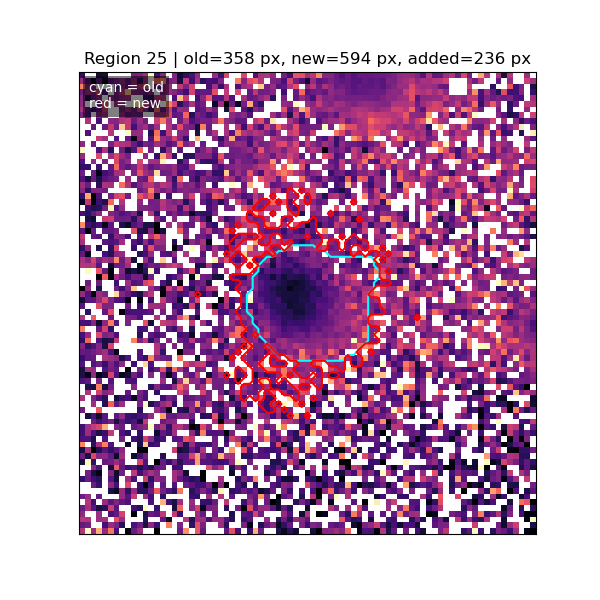

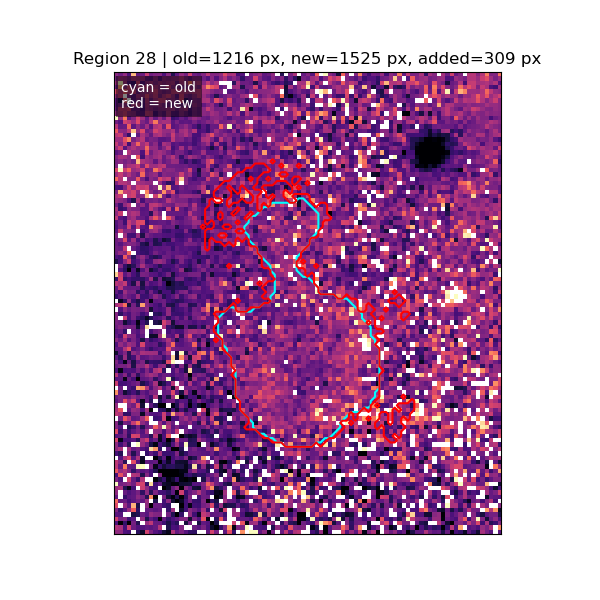

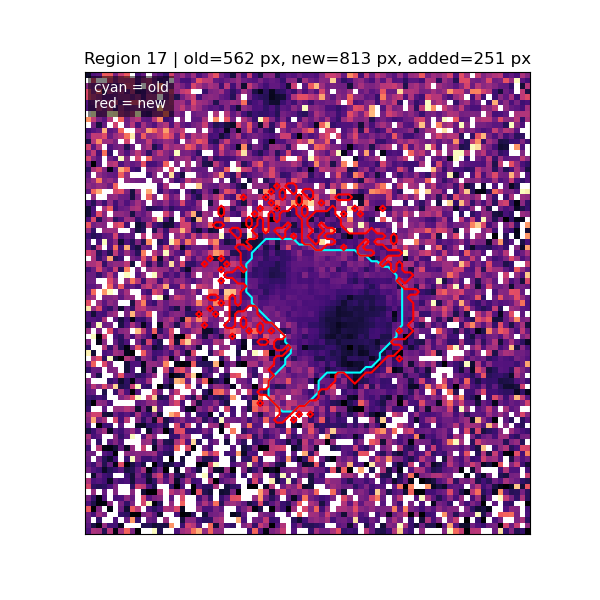

'\nplot_old_new_regions(\n    labels_old=labels_data,\n    labels_new=labels_refined,\n    image=detection,\n    n_regions=8,\n    random_state=2)\n    '

In [64]:
def plot_old_new_regions(labels_old, labels_new, image, region_ids=None,
    n_regions=8, pad=20, random_state=42, image_label="Hα + [OIII]"):

    rng = np.random.default_rng(random_state)

    all_ids = np.unique(labels_old)
    all_ids = all_ids[all_ids != 0]

    # Only keep regions that actually changed
    changed_ids = []
    for rid in all_ids:
        old_mask = labels_old == rid
        new_mask = labels_new == rid
        if np.any(old_mask != new_mask):
            changed_ids.append(rid)

    changed_ids = np.array(changed_ids)

    if region_ids is None:
        if len(changed_ids) == 0:
            print("No regions changed.")
            return

        n_pick = min(n_regions, len(changed_ids))
        region_ids = rng.choice(changed_ids, size=n_pick, replace=False)
    else:
        region_ids = np.array(region_ids)

    for rid in region_ids:
        old_mask = labels_old == rid
        new_mask = labels_new == rid

        if old_mask.sum() == 0 and new_mask.sum() == 0:
            continue

        combined = old_mask | new_mask
        ys, xs = np.where(combined)

        y0 = max(ys.min() - pad, 0)
        y1 = min(ys.max() + pad + 1, labels_old.shape[0])
        x0 = max(xs.min() - pad, 0)
        x1 = min(xs.max() + pad + 1, labels_old.shape[1])

        img_cut = image[y0:y1, x0:x1]
        old_cut = old_mask[y0:y1, x0:x1]
        new_cut = new_mask[y0:y1, x0:x1]

        added_cut = new_cut & (~old_cut)

        #vmin, vmax = np.nanpercentile(img_cut[np.isfinite(img_cut)], [1, 99])

        fig, ax = plt.subplots(figsize=(6, 6))

        ax.imshow(percentile_norm(img_cut), origin="lower", cmap="magma")

        ax.contour(old_cut.astype(float), levels=[0.5], colors="cyan", linewidths=1.5)
        ax.contour(new_cut.astype(float), levels=[0.5], colors="red", linewidths=1.5)

        ax.set_title(f"Region {rid} | old={old_mask.sum()} px, new={new_mask.sum()} px, added={added_cut.sum()} px")

        ax.text(
            0.02, 0.98,
            "cyan = old\nred = new",
            transform=ax.transAxes,
            va="top",
            ha="left",
            color="white",
            bbox=dict(facecolor="black", alpha=0.5, edgecolor="none"))

        ax.set_xticks([])
        ax.set_yticks([])
        plt.show()

plot_old_new_regions(
    labels_old=labels_data,
    labels_new=new_labels,
    image=log_sii_oiii,
    n_regions=8,
    random_state=4,
    image_label="log([SII]/[OIII])")
'''
plot_old_new_regions(
    labels_old=labels_data,
    labels_new=labels_refined,
    image=detection,
    n_regions=8,
    random_state=2)
    '''

In [ ]:
labels_data = labels_refined.copy()
regions = make_cat(labels_data)
regions.to_csv("HII_dendro_ipm.csv", index=False)
fits.writeto("HII_labels_refined.fits", labels_refined.astype(np.int32), header, overwrite=True)